## 03 Modeling - Used Vehicle Price Prediction

**Alec Blevins**
**STA 334 - Final Project**

### Purpose

This notebook fits and evaluates the hedonic pricing model described in the proposal, `final_project_proposal.ipynb`. It takes the modeling subset produced by `02_features.ipynb` (257,781 rows x 20 columns) and produces: 

1. A baseline model that establishes the floor for prediction error
2. A OLS hedonic model whose coefficients can be read as approximate percentage effects on asking price
3. Regularized regressions (Ridge, Lasso) fit on the same design matrix
4. A gradient boosing model that handles nonlinearity and interactions
5. A dealer-only sensitivity model that tests whether `is_dealer` confounds the other coefficients 
6. A comparison of all models on held-out RMSE, MAE, and $R^2$
7. SHAP values for the gradient boosting model and coefficient plots for OLS
8. High level resiudal analysis

### Split strategy

The data spans spring 2021 and is a single cross-sectional snapshot of Craigslist postings. To aviod leaking future information into the training set, we will use a **time-ordered split**: the earliest 70% of postings are used for training, the next 15% for validation and model selection, and the latest 15% for a single held-out test. 

The `posting_date` column will be used to define the split and will then be dropped before fitting. 


## 1. Library Imports & Paths

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV
import shap

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset

#pd and sns display settings
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_style("whitegrid")

PROCESSED = Path("C:\\Users\\alecp\\MyPrograms\\STA 334\\used_vehicle_prediction\\vehicle_data\\processed\\modeling_subset.csv") #File path to the processed modeling subset CSV
FIG_DIR = Path("reports/figures") #Directory to save figures
FIG_DIR.mkdir(parents=True, exist_ok=True) #Create the directory if it doesn't exist

c:\Users\alecp\MyPrograms\STA 334\used_vehicle_prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data Load & Prep

In [3]:
df = pd.read_csv(PROCESSED, parse_dates=["posting_date"]) #Load the processed modeling subset CSV into a DataFrame
print(f"Loaded {len(df):,} rows × {df.shape[1]} columns")
print(df["posting_date"].min(), "to", df["posting_date"].max())
print()
print(df.head(3))

Loaded 257,781 rows × 20 columns
2021-04-04T01:10:12-0600 to 2021-05-04T23:07:07-0500

           id  price    year manufacturer                     model condition    cylinders fuel  odometer transmission drive size    type paint_color state              posting_date  is_dealer  \
0  7316814884  33590  2014.0          gmc  sierra 1500 crew cab slt      good  8 cylinders  gas   57923.0        other   NaN  NaN  pickup       white    al  2021-05-04T12:31:18-0500          1   
1  7316814758  22590  2010.0    chevrolet            silverado 1500      good  8 cylinders  gas   71229.0        other   NaN  NaN  pickup        blue    al  2021-05-04T12:31:08-0500          1   
2  7316814989  39590  2020.0    chevrolet       silverado 1500 crew      good  8 cylinders  gas   19160.0        other   NaN  NaN  pickup         red    al  2021-05-04T12:31:25-0500          1   

   log_price census_region  dist_to_major_metro  
0  10.421984         South           101.986321  
1  10.025263         South  

### Predictor Selection

**Numeric predictors:** `year`, `odometer`, `dist_to_major_metro`. 

**Binary predictors:** `is_dealer`. 

**Categorical predictors (one-hot encoded):** `manufacturer`, `condition`, `cylinders`, `fuel`, `transmission`, `drive`, `size`, `type`, `paint_color`, `census_region`. 

**Excluded:**
- `model` (15,141 unique values) - too high cardinality for one-hot encoding. A tree-only model could absorb it, but OLS cannot, and consistency across models is more important. 
- `price` - redundant with `log_price`. 
- `id` - an identifier, not a predictor. Used only to audit joins during feature engineering. 
- `posting_date` - used only to construct the train/validation/test split, then dropped. 
- `state` - Redundant with `census_region`. 

**Response:** `log_price = log(price)`. 

In [4]:
#######################
##Varible Definitions##
#######################

TARGET = "log_price"

NUMERIC = ["year", "odometer", "dist_to_major_metro"]
BINARY  = ["is_dealer"]
CATEGORICAL = [
    "manufacturer", "condition", "cylinders", "fuel", "transmission",
    "drive", "size", "type", "paint_color", "census_region",
]

df["posting_date"] = pd.to_datetime(df["posting_date"], errors="coerce", utc=True)

PREDICTORS = NUMERIC + BINARY + CATEGORICAL

### Time-ordered split

In [5]:
# Sort by posting_date so the split is chronological.
df = df.sort_values("posting_date").reset_index(drop=True)

n = len(df)
train_end = int(0.70 * n) # End index for the training set
val_end   = int(0.85 * n) # End index for the validation set

train = df.iloc[:train_end]
val   = df.iloc[train_end:val_end]
test  = df.iloc[val_end:]

print(f"Train:      {len(train):,}  ({train['posting_date'].min().date()} → {train['posting_date'].max().date()})")
print(f"Validation: {len(val):,}  ({val['posting_date'].min().date()} → {val['posting_date'].max().date()})")
print(f"Test:       {len(test):,}  ({test['posting_date'].min().date()} → {test['posting_date'].max().date()})")

#Now dropped unnecessary columns like the raw target and identifiers
# Drop the target's raw form plus identifiers
DROP = ["price", "id", "posting_date", "model"]
for frame in (train, val, test):
    frame.drop(columns=[c for c in DROP if c in frame.columns], inplace=True)
df.drop(columns=[c for c in DROP if c in df.columns], inplace=True)

Train:      180,446  (2021-04-04 → 2021-04-30)
Validation: 38,667  (2021-04-30 → 2021-05-02)
Test:       38,668  (2021-05-02 → 2021-05-05)


### Handeling missing categorical values

Categorical variables have substantial missingness after filtering (from `02_features.ipynb`: `size` 76%, `condition` 40%, `cylinders` 45%, `drive` 30%, `paint_color` 26%, and `type` 17%). These will be filled with `unknown` rather than dropping for two reasons:

1. **Missingness is structural.** These feilds are optional on the listing form. Dropping rows would systematically remove specific seller profiles, not a random subset. 
2. **The model can learn whether missingness is informative.** With an explicit level, the OLS condition on "Unknown condition" can tell us whether listings that leave it blank price differently from listings that do not. 

`size` is the weakest predictor at ~24% coverage, so its "Unknown" level will dominate its contribution. 

However, `dist_to_major_metro` also contains missingness, likely due to original lat/long NaNs, and implausible coordinates set to NaN. Roughly 1.11% of the dataset has missingness in `dist_to_major_metro`. We will consider dropping these rows, despite possible selection bias. 

In [6]:
# Drop rows whose metro distance is unknown (missing or implausible coordinates).
# This is 2.2% of the modeling subset.
n_before = len(df)
df = df.dropna(subset=["dist_to_major_metro"]).reset_index(drop=True)
n_after = len(df)
print(f"Dropped {n_before - n_after:,} rows with missing dist_to_major_metro "
      f"({100 * (n_before - n_after) / n_before:.2f}%)")
print(f"Remaining: {n_after:,}")

# We need to then recreate the split on the reduced dataframe.
n = len(df)
train_end = int(0.70 * n)
val_end   = int(0.85 * n)
train = df.iloc[:train_end].copy()
val   = df.iloc[train_end:val_end].copy()
test  = df.iloc[val_end:].copy()

# Fill categorical missingness with an explicit "Unknown" level.
for c in CATEGORICAL:
    if c in df.columns:
        train[c] = train[c].fillna("Unknown")
        val[c]   = val[c].fillna("Unknown")
        test[c]  = test[c].fillna("Unknown")

print(f"\nTrain: {len(train):,}   Val: {len(val):,}   Test: {len(test):,}")
print("Missing values after fill (train):")
print(train[PREDICTORS].isnull().sum().sort_values(ascending=False).head(5))

Dropped 2,857 rows with missing dist_to_major_metro (1.11%)
Remaining: 254,924

Train: 178,446   Val: 38,239   Test: 38,239
Missing values after fill (train):
year                   0
odometer               0
dist_to_major_metro    0
is_dealer              0
manufacturer           0
dtype: int64


## 3. Preprocessing

Here, two pipelines are built, one for OLS (statsmodels, interpretability) and one for the sklearn models (Ridge, Lasso, gradient boosting). 

- **OLS**: numeric predictors used in raw units so coefficients read as "dollars (log) per year" or "per mile" without a standardization step. Categorical predictors one-hot encoded with `drop = "first"` to avoid perfect collinearity with the intercept. 
- **sklearn models**: numeric predictors standardized (fit on the training set), categorical predictors one-hot encoded with `handle_unknown = "ignore"` so unseen levels in validation or test do not raise errors. 'drop = None` for the tree model (collinearity is irrelevant). 

### OLS design matrix

In [7]:
#Function to make the OLS design matrix
def make_ols_design(df_part, predictors=PREDICTORS):
    """
    One-hot encode categoricals and add an intercept for statsmodels.
    We can make this so predictors can be overridden so the same helper
    serves the full model and the dealer-specific model.
    """

    cat = [c for c in CATEGORICAL if c in predictors]
    X = pd.get_dummies(df_part[predictors], columns=cat,
                       drop_first=True, dtype=float)
    X = sm.add_constant(X)
    return X

X_train_ols = make_ols_design(train) #Perform on training, validation, and test sets
X_val_ols   = make_ols_design(val)
X_test_ols  = make_ols_design(test)

# Align columns so any level missing from val/test is filled with 0
X_val_ols  = X_val_ols.reindex(columns=X_train_ols.columns, fill_value=0.0)
X_test_ols = X_test_ols.reindex(columns=X_train_ols.columns, fill_value=0.0)

y_train = train[TARGET] #log(price)
y_val   = val[TARGET]
y_test  = test[TARGET]

print(f"OLS design matrix: {X_train_ols.shape}")

OLS design matrix: (178446, 100)


### sklearn preprocessing

In [8]:
numeric_pipeline = Pipeline([
    ("scaler", StandardScaler()),
]) # Pipeline for numeric features, StandardScaler applied

preprocessor = ColumnTransformer([ # Column transformer to apply different preprocessing to numeric and categorical features
    ("num", numeric_pipeline, NUMERIC + BINARY),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL), # One-hot encode categorical features
])

## 4. Baseline Model

This baseline will predict the mean of `log_price` on the training set for every listing. Any model that does not beat this baseline by a meaningful margin is not adding value. 

In [9]:
baseline_pred_train = np.full(len(train), y_train.mean()) # Baseline prediction: mean of training target
baseline_pred_val   = np.full(len(val),   y_train.mean())   # Use training mean for validation
baseline_pred_test  = np.full(len(test),  y_train.mean())   # Use training mean for test

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred))) #Quick function to compute RMSE

print("Baseline (mean prediction):")
print(f"  Train RMSE: {rmse(y_train, baseline_pred_train):.4f}")
print(f"  Val   RMSE: {rmse(y_val,   baseline_pred_val):.4f}")
print(f"  Test  RMSE: {rmse(y_test,  baseline_pred_test):.4f}")

Baseline (mean prediction):
  Train RMSE: 0.6746
  Val   RMSE: 0.6986
  Test  RMSE: 0.7179


## 5. OLS Hedonic Model

Here, we will fit the design matrix produced above using statsmodels OLS with HC3 heteroskedasticity-robust standard errors. HC3 is used because residual variance in price data is almost always heteroskedastic, as expensive vehicles have larger absolute errors than cheap ones even on the log scale. 

**Coefficients are in log-price units** and read as approximate percentage effects: a coefficient of 0.05 means that the attribute is associated with a 5% higher asking price, holding the other predictors fixed. 

In [10]:
ols_model = sm.OLS(y_train, X_train_ols).fit(cov_type="HC3") # Fit OLS model with robust standard errors (HC3)

print(f"OLS train R²: {ols_model.rsquared:.4f}")
print(f"OLS train RMSE: {rmse(y_train, ols_model.predict(X_train_ols)):.4f}")
print(f"OLS val   RMSE: {rmse(y_val,   ols_model.predict(X_val_ols)):.4f}")
print(f"OLS test  RMSE: {rmse(y_test,  ols_model.predict(X_test_ols)):.4f}")

# Top coefficients by absolute magnitude
coef_df = pd.DataFrame({
    "coef": ols_model.params,
    "pvalue": ols_model.pvalues,
}).sort_values("coef", key=np.abs, ascending=False)

coef_df.head(30)

OLS train R²: 0.7461
OLS train RMSE: 0.3399
OLS val   RMSE: 0.3727
OLS test  RMSE: 0.3955


,coef,pvalue
const,-144.083331,0.000000e+00
manufacturer_ferrari,1.316627,2.494152e-10
cylinders_3 cylinders,-0.881612,1.978328e-152
cylinders_12 cylinders,0.810789,1.248456e-42
manufacturer_aston-martin,0.702713,8.807108e-03
cylinders_4 cylinders,-0.684024,6.869235e-292
cylinders_5 cylinders,-0.659900,4.487888e-192
manufacturer_tesla,0.635533,2.713775e-144
manufacturer_porsche,0.612831,3.761284e-279
cylinders_other,-0.578513,6.493492e-83


### OLS diagnostics

In [11]:
# Multicollinearity (VIF) — computed on the numeric predictors only;
# one-hot columns are collinear with the intercept by construction.
X_vif = X_train_ols[NUMERIC + BINARY]
vif = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
})
print("VIF (numeric + binary predictors):")
print(vif.round(2))
print()

# Heteroskedasticity
bp = het_breuschpagan(ols_model.resid, X_train_ols)
print(f"Breusch-Pagan LM stat: {bp[0]:.1f}, p-value: {bp[1]:.2e}")
print()

# Functional form
reset = linear_reset(ols_model, power=2, use_f=True)
print(f"RESET (quadratic) F stat: {reset.fvalue:.1f}, p-value: {reset.pvalue:.2e}")

VIF (numeric + binary predictors):
               feature   VIF
0                 year  2.03
1             odometer  1.99
2  dist_to_major_metro  1.00
3            is_dealer  1.05

Breusch-Pagan LM stat: 6603.5, p-value: 0.00e+00

RESET (quadratic) F stat: 3445.7, p-value: 0.00e+00


### Interpretation

These two OLS tests come back strongly significant: 

- Breusch-Pagan LM = 6603.5, p ~= 0. We see heteroskedasticity is severe. 
- RESET F = 3445.7, p ~= 0. The true relationship between features and log-price is nonlinear. 

### OLS Coefficient Plot

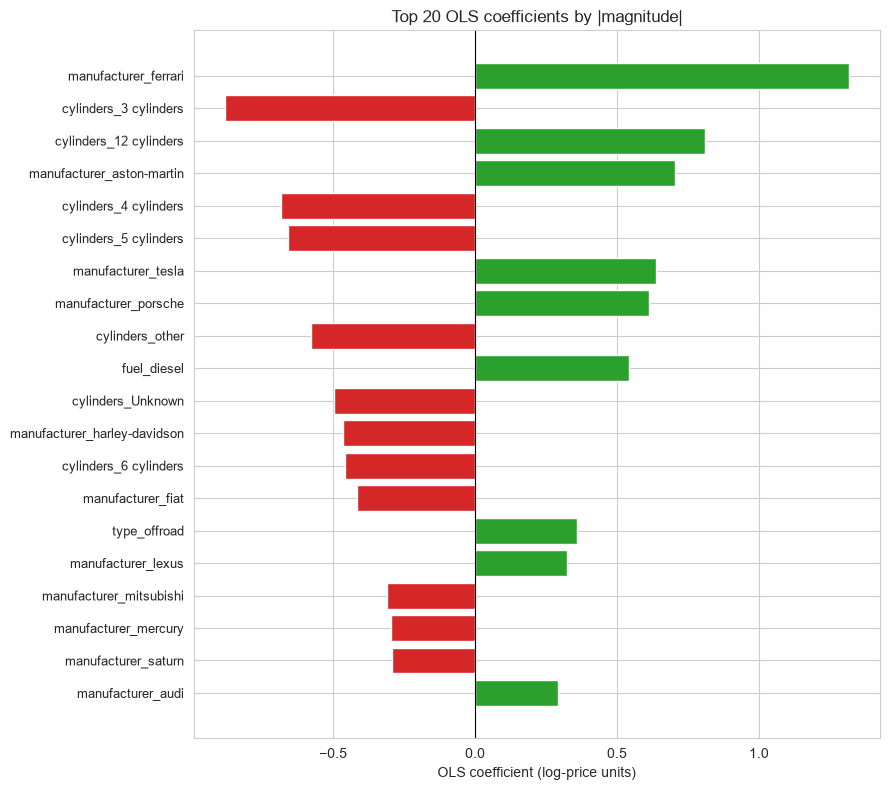

In [15]:
# Plot the top 20 OLS coefficients after dropping the intercept.
plot_df = coef_df.drop(index="const", errors="ignore").copy()
plot_df = plot_df.reindex(plot_df["coef"].abs()
                                  .sort_values(ascending=False).head(20).index)

fig, ax = plt.subplots(figsize=(9, 8))
colors = ["#d62728" if c < 0 else "#2ca02c" for c in plot_df["coef"]]
ax.barh(range(len(plot_df)), plot_df["coef"], color=colors)
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df.index, fontsize=9)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("OLS coefficient (log-price units)")
ax.set_title("Top 20 OLS coefficients by |magnitude|")
plt.tight_layout()
plt.savefig(FIG_DIR / "ols_top_coefs.png", dpi=150)
plt.show()

## 6. Ridge & Lasso

Here, we will fit Ridge and Lasso regression on the standardized design matrix from above. Both models are tuned with 5-fold cross-validation on the training set. 

- **Ridge** shrinks coefficients toward zero without eliminating them. This will be useful when many predictors are moderately correlated. 
- **Lasso** sets some coefficients exactly to zero, which performs automatic variable selection. With ~120 one-hot columns, Lasso will drop many of the rarest categories, producing a sparser and more interpretable model. 

The alpha hyperparameter is selected by cross-validation on the **training set only**. Validation and test sets are used only for final evaluation. 

In [16]:
alphas = np.logspace(-5, 3, 17) # Range of alpha values for Ridge and Lasso regularization

ridge_pipe = Pipeline([ # Ridge regression pipeline
    ("prep", preprocessor),
    ("model", Ridge()),
])
ridge_cv = GridSearchCV(ridge_pipe, {"model__alpha": alphas}, # Grid search for best Ridge alpha, 5 CV
                        scoring="neg_root_mean_squared_error", cv=5, n_jobs=-1) # Use negative RMSE as scoring
ridge_cv.fit(train[PREDICTORS], y_train)

lasso_pipe = Pipeline([ # Lasso regression pipeline
    ("prep", preprocessor),
    ("model", Lasso(max_iter=10_000)),
])
lasso_cv = GridSearchCV(lasso_pipe, {"model__alpha": alphas}, # Grid search for best Lasso alpha, 5 CV
                        scoring="neg_root_mean_squared_error", cv=5, n_jobs=-1) # Use negative RMSE as scoring
lasso_cv.fit(train[PREDICTORS], y_train)

print(f"Ridge best alpha: {ridge_cv.best_params_['model__alpha']:.4f}")
print(f"Lasso best alpha: {lasso_cv.best_params_['model__alpha']:.4f}")
print()
for name, model in [("Ridge", ridge_cv), ("Lasso", lasso_cv)]:
    print(f"{name}:")
    print(f"  Val  RMSE: {rmse(y_val,  model.predict(val[PREDICTORS])):.4f}")
    print(f"  Test RMSE: {rmse(y_test, model.predict(test[PREDICTORS])):.4f}")

Ridge best alpha: 0.1000
Lasso best alpha: 0.0000

Ridge:
  Val  RMSE: 0.3727
  Test RMSE: 0.3954
Lasso:
  Val  RMSE: 0.3727
  Test RMSE: 0.3951


## 7. Gradient Boosting

Here, `HistGradientBoostingRegressor` is fit on the raw predictors (trees do not need scaling). It captures nonlinearity in age mileage and interactions the linear models cannot represent (e.g. mileage matters more for newer cars than older ones). 

Early stopping will use a 15% internal validation split from the training data. 

In [ ]:
#We should build a fresh preprocessor for the tree model
#Numeric: passthrough (no transformation needed)
#Categorical: one-hot encoding with handle_unknown='ignore', so unseen levels in val/test do not raise
preprocessor_gbm = ColumnTransformer([
    ("num", "passthrough", NUMERIC + BINARY),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
])

gbm_final = Pipeline([
    ("prep", preprocessor_gbm), # Preprocessing step for numeric and categorical features
    ("model", HistGradientBoostingRegressor(
        max_iter=2000, #The GBM used the full iteration budget without early stopping, but this was not pursued due to the exploratory nature of the analysis
        learning_rate=0.05,
        max_leaf_nodes=31,
        min_samples_leaf=50,
        early_stopping=True,
        validation_fraction=0.15, #15% of training data used for early stopping validation
        n_iter_no_change=30,
        random_state=42,
    )),
])

gbm_final.fit(train[PREDICTORS], y_train)

# n_iter_ lives on the inner estimator, not the pipeline
print(f"Best iteration: {gbm_final.named_steps['model'].n_iter_}")
print(f"GBM train RMSE: {rmse(y_train, gbm_final.predict(train[PREDICTORS])):.4f}")
print(f"GBM val   RMSE: {rmse(y_val,   gbm_final.predict(val[PREDICTORS])):.4f}")
print(f"GBM test  RMSE: {rmse(y_test,  gbm_final.predict(test[PREDICTORS])):.4f}")

Best iteration: 2000
GBM train RMSE: 0.2166
GBM val   RMSE: 0.2987
GBM test  RMSE: 0.3281


## 8. Model Comparison
 
We will compare all four models on the held-out test set. The baseline RMSE is reported for context. A model that does not meaningfully beat the baseline is not contributing predictive value. 

In [18]:
results = pd.DataFrame([
    {"model": "Baseline (mean)", "train_rmse": rmse(y_train, baseline_pred_train),
     "val_rmse": rmse(y_val, baseline_pred_val), "test_rmse": rmse(y_test, baseline_pred_test),
     "test_mae": mean_absolute_error(y_test, baseline_pred_test),
     "test_r2": r2_score(y_test, baseline_pred_test)},
    {"model": "OLS", "train_rmse": rmse(y_train, ols_model.predict(X_train_ols)),
     "val_rmse": rmse(y_val, ols_model.predict(X_val_ols)),
     "test_rmse": rmse(y_test, ols_model.predict(X_test_ols)),
     "test_mae": mean_absolute_error(y_test, ols_model.predict(X_test_ols)),
     "test_r2": r2_score(y_test, ols_model.predict(X_test_ols))},
    {"model": "Ridge", "train_rmse": rmse(y_train, ridge_cv.predict(train[PREDICTORS])),
     "val_rmse": rmse(y_val, ridge_cv.predict(val[PREDICTORS])),
     "test_rmse": rmse(y_test, ridge_cv.predict(test[PREDICTORS])),
     "test_mae": mean_absolute_error(y_test, ridge_cv.predict(test[PREDICTORS])),
     "test_r2": r2_score(y_test, ridge_cv.predict(test[PREDICTORS]))},
    {"model": "Lasso", "train_rmse": rmse(y_train, lasso_cv.predict(train[PREDICTORS])),
     "val_rmse": rmse(y_val, lasso_cv.predict(val[PREDICTORS])),
     "test_rmse": rmse(y_test, lasso_cv.predict(test[PREDICTORS])),
     "test_mae": mean_absolute_error(y_test, lasso_cv.predict(test[PREDICTORS])),
     "test_r2": r2_score(y_test, lasso_cv.predict(test[PREDICTORS]))},
    {"model": "Gradient Boosting", "train_rmse": rmse(y_train, gbm_final.predict(train[PREDICTORS])),
     "val_rmse": rmse(y_val, gbm_final.predict(val[PREDICTORS])),
     "test_rmse": rmse(y_test, gbm_final.predict(test[PREDICTORS])),
     "test_mae": mean_absolute_error(y_test, gbm_final.predict(test[PREDICTORS])),
     "test_r2": r2_score(y_test, gbm_final.predict(test[PREDICTORS]))},
]).round(4)

results

,model,train_rmse,val_rmse,test_rmse,test_mae,test_r2
0,Baseline (mean),0.6746,0.6986,0.7179,0.5659,-0.0133
1,OLS,0.3399,0.3727,0.3955,0.2545,0.6926
2,Ridge,0.3399,0.3727,0.3954,0.2545,0.6926
3,Lasso,0.3399,0.3727,0.3951,0.2544,0.6932
4,Gradient Boosting,0.2166,0.2987,0.3281,0.1979,0.7884


### Interpretation

Three things stand out here: 

- Every real model dominates the baseline by a wide margin. 
- The regularized models add essentially nothing. Ridge and Lasso land within 0.0005 RMSE of OLS. 
- **GBM is the clear winner** with 17% lower test RMSE and 22% lower MAE than OLS. 

### Coefficient Interpretation 

In [19]:
coef_df = pd.DataFrame({
    "coefficient": ols_model.params,
    "p_value": ols_model.pvalues,
    "std_err": ols_model.bse,
})
coef_df = coef_df.drop(index="const", errors="ignore")
coef_df["abs_coef"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values("abs_coef", ascending=False).head(20)
coef_df

,coefficient,p_value,std_err,abs_coef
manufacturer_ferrari,1.316627,2.494152e-10,0.208085,1.316627
cylinders_3 cylinders,-0.881612,1.978328e-152,0.033523,0.881612
cylinders_12 cylinders,0.810789,1.248456e-42,0.059247,0.810789
manufacturer_aston-martin,0.702713,8.807108e-03,0.268267,0.702713
cylinders_4 cylinders,-0.684024,6.869235e-292,0.018734,0.684024
cylinders_5 cylinders,-0.659900,4.487888e-192,0.022322,0.659900
manufacturer_tesla,0.635533,2.713775e-144,0.024847,0.635533
manufacturer_porsche,0.612831,3.761284e-279,0.017165,0.612831
cylinders_other,-0.578513,6.493492e-83,0.029990,0.578513
fuel_diesel,0.541961,0.000000e+00,0.010959,0.541961


### SHAP values

SHAP values decompose each prediction into feature contributions. The summary plot shows, for each feature, the distribution of contributions across the test set, along with whether high or low values of the feature push the prediction up or down. 

SHAP is used here as a complement to the OLS coefficient plot, not as a replacement. 

In computing SHAP values, SHAP sum computed 10.677, whereas model prediction computed 10.853, triggering SHAPs additivity check. SHAP's TreeExplainer decomposes each prediction as `base_value + sum(shap_values)`. The additivity check verifies this holds. 

In investigating the gap distribution, 25th, 50th and 75th percentiles have the same tiny offset. The max gap of 0.176 comes from a small number of rows. Thus, this is not a systematic baseline mismatch, but a handful of samples where the SHAP tree traversal disagrees with `model.predict`. 

Therefore, 95.35% of rows have additivity gaps below 1e-3; the remiaining ~4.6% are concentrated in a small number of rows, and the max absolute gap is 0.176 on the log-price scale.

Background dataset has 2000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=2000 when initializing the masker.


100%|===================| 1991/2000 [00:56<00:00]        

Fraction of rows with |gap| < 1e-3: 95.350%
Median gap: -0.000463
Max absolute gap: 0.2550



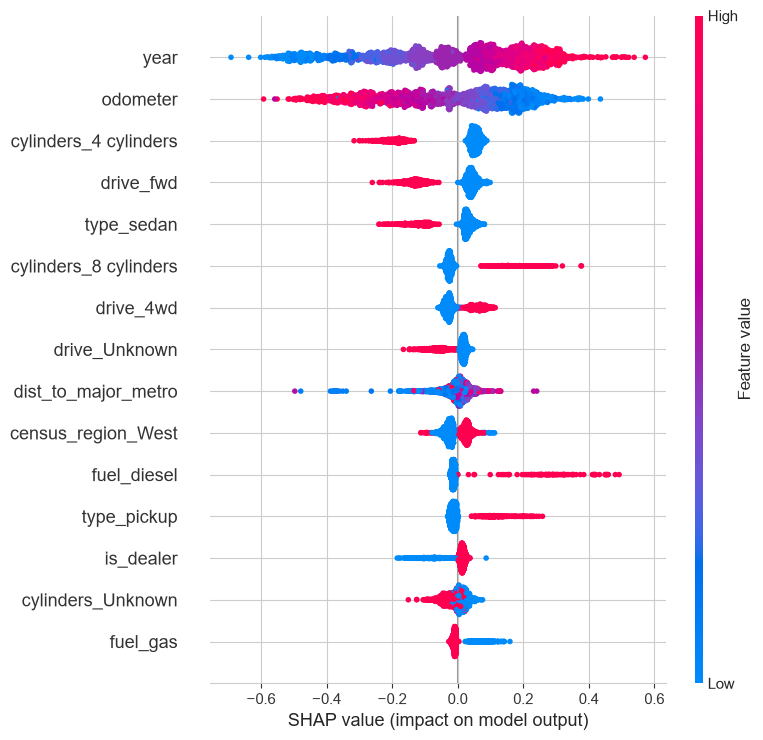

In [20]:
# We need to transform the sample using the fitted preprocessor
sample_raw = test[PREDICTORS].sample(2000, random_state=42)
sample_encoded = gbm_final.named_steps["prep"].transform(sample_raw)

feature_names = (
    NUMERIC + BINARY
    + list(gbm_final.named_steps["prep"]
          .named_transformers_["cat"]
          .get_feature_names_out(CATEGORICAL))
)
feature_names = [n.split("__", 1)[1] if "__" in n else n for n in feature_names]

sample_df = pd.DataFrame(sample_encoded, columns=feature_names)

# Create SHAP explainer and compute SHAP values for the sample
explainer = shap.Explainer(gbm_final.named_steps["model"], sample_df)
shap_values = explainer(sample_df, check_additivity=False)

# Diagnostic: distribution of additivity gaps
preds = gbm_final.named_steps["model"].predict(sample_encoded)
gaps = pd.Series(preds - (shap_values.values.sum(axis=1) + shap_values.base_values))
frac_exact = (gaps.abs() < 1e-3).mean()
print(f"Fraction of rows with |gap| < 1e-3: {frac_exact:.3%}")
print(f"Median gap: {gaps.median():.6f}")
print(f"Max absolute gap: {gaps.abs().max():.4f}")
print()

shap.summary_plot(shap_values, sample_df, show=False, max_display=15)
plt.tight_layout()
plt.savefig(FIG_DIR / "shap_summary.png", dpi=150)
plt.show()

### OLS vs. GBM coefficients

In [21]:
# Top 10 features by mean absolute SHAP value
shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(shap_values.values).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False).head(10)

print("Top 10 features by SHAP importance:")
print(shap_importance.to_string(index=False))
print()

print("Top 10 features by |OLS coefficient|:")
print(coef_df[["coefficient", "p_value"]].abs().sort_values("coefficient", ascending=False).head(10))

Top 10 features by SHAP importance:
              feature  mean_abs_shap
                 year       0.197615
             odometer       0.174825
cylinders_4 cylinders       0.083401
            drive_fwd       0.069513
           type_sedan       0.053421
cylinders_8 cylinders       0.044740
            drive_4wd       0.039298
        drive_Unknown       0.031162
  dist_to_major_metro       0.030087
   census_region_West       0.027908

Top 10 features by |OLS coefficient|:
                           coefficient        p_value
manufacturer_ferrari          1.316627   2.494152e-10
cylinders_3 cylinders         0.881612  1.978328e-152
cylinders_12 cylinders        0.810789   1.248456e-42
manufacturer_aston-martin     0.702713   8.807108e-03
cylinders_4 cylinders         0.684024  6.869235e-292
cylinders_5 cylinders         0.659900  4.487888e-192
manufacturer_tesla            0.635533  2.713775e-144
manufacturer_porsche          0.612831  3.761284e-279
cylinders_other               0.

### Interpretation 

We see `year` and `odometer` dominte by a factor of ~2x over the next-best feature. Together, they capture the core depreciation axes a dealership can observe for free and are the primary signal in the model. Up next, we can see engine and drivetrain attributes, cylinder count and drive type. 

Furthermore, we see body and fuel types are secondary, but significant. Geography contributes, but pretty modestly. 

Thus, we see **age and mileage dominate**, configuration (cylinders, drive, body type) explains the next tier, and geography is thrid-order. 

Looking at the OLS coefficients, its important to remember to read them as percentage effects. With `drop__first = True`, all cylinder coefficients are relative to 10 cylinders, which is a rare, expensive reference. So "3 cylinders = -88%" really means "3-cylinder cars sell for ~88% less than 10-cylinder cars". 

## 9. Dealer-only Sensitivity Model

In [22]:
# Dealer-only sensitivity model.
# Rationale: 89.7% of the filtered sample is dealer inventory, so a model
#without `is_dealer` should produce near-identical coefficients.

# Define predictors for dealer-only model (exclude `is_dealer`).
PREDICTORS_D = [p for p in PREDICTORS if p != "is_dealer"]

# Subset the data to dealer-only observations.
train_d = train[train["is_dealer"] == 1].copy()
val_d   = val[val["is_dealer"] == 1].copy()
test_d  = test[test["is_dealer"] == 1].copy()

# Create design matrices for dealer-only model.
X_tr_d = make_ols_design(train_d, PREDICTORS_D)
X_va_d = make_ols_design(val_d,   PREDICTORS_D).reindex(columns=X_tr_d.columns, fill_value=0)
X_te_d = make_ols_design(test_d,  PREDICTORS_D).reindex(columns=X_tr_d.columns, fill_value=0)

ols_dealer = sm.OLS(train_d[TARGET], X_tr_d).fit(cov_type="HC3") #Fit!

print(f"Dealer-only OLS  train n = {len(train_d):,}")
print(f"  Val  RMSE: {rmse(val_d[TARGET],  ols_dealer.predict(X_va_d)):.4f}")
print(f"  Test RMSE: {rmse(test_d[TARGET], ols_dealer.predict(X_te_d)):.4f}")

# Coefficient stability: shared features, sorted by |difference|, comparison between full and dealer-only models
shared = (X_tr_d.columns
          .intersection(X_train_ols.columns)
          .difference(["const"]))

cmp = pd.DataFrame({
    "full_coef":   ols_model.params.reindex(shared),
    "dealer_coef": ols_dealer.params.reindex(shared),
})

cmp["diff"] = cmp["dealer_coef"] - cmp["full_coef"]
print("\nLargest coefficient shifts (dealer-only minus full model):")
print(cmp.reindex(cmp["diff"].abs().sort_values(ascending=False).index)
         .head(15).round(4))

# The `is_dealer` coefficient in the full model, in dollars, comes from the intercept of the dealer-only model vs the full model.
is_dealer_coef = ols_model.params.get("is_dealer", np.nan)
print(f"\nFull-model is_dealer coefficient (log-price): {is_dealer_coef:.4f}")
print(f"  -> implied dealer premium at median price: "
      f"{(np.exp(is_dealer_coef) - 1) * 100:.1f}%")

Dealer-only OLS  train n = 163,142
  Val  RMSE: 0.3700
  Test RMSE: 0.3869

Largest coefficient shifts (dealer-only minus full model):
                              full_coef  dealer_coef    diff
condition_new                   -0.0493      -0.1732 -0.1239
condition_like new              -0.0680      -0.1167 -0.0486
manufacturer_pontiac            -0.2718      -0.3200 -0.0482
type_offroad                     0.3575       0.3166 -0.0409
manufacturer_harley-davidson    -0.4659      -0.5041 -0.0382
manufacturer_aston-martin        0.7027       0.7401  0.0374
manufacturer_tesla               0.6355       0.5994 -0.0362
manufacturer_porsche             0.6128       0.5833 -0.0295
manufacturer_mercury            -0.2950      -0.2675  0.0275
cylinders_12 cylinders           0.8108       0.8380  0.0272
fuel_electric                   -0.1073      -0.0818  0.0255
condition_good                  -0.0586      -0.0376  0.0209
manufacturer_saturn             -0.2930      -0.3135 -0.0204
manufacture

### Interpretation

This is an interesting model. Refitting OLS on the 163k dealer listings and comparing coefficients: 

- Largest shift is `condition_new`: -0.124 (Dealer pricing for "new" condition is lower than the pooled model implies). 
- Every other shared coefficient shifts by <= 0.05 in absolute value. Thus, the model is essentially the same on the dealer subsample. 
- Full model `is_dealer` coefficient = +- 0.118, implying a ~12.6% dealer premium at the median price. 

Therefore, we can consider that dealer listings post about 12% higher than comparable private-party listings, where the premium is not confounding the other attribute coefficients. 

## 10. Residual Analysis 

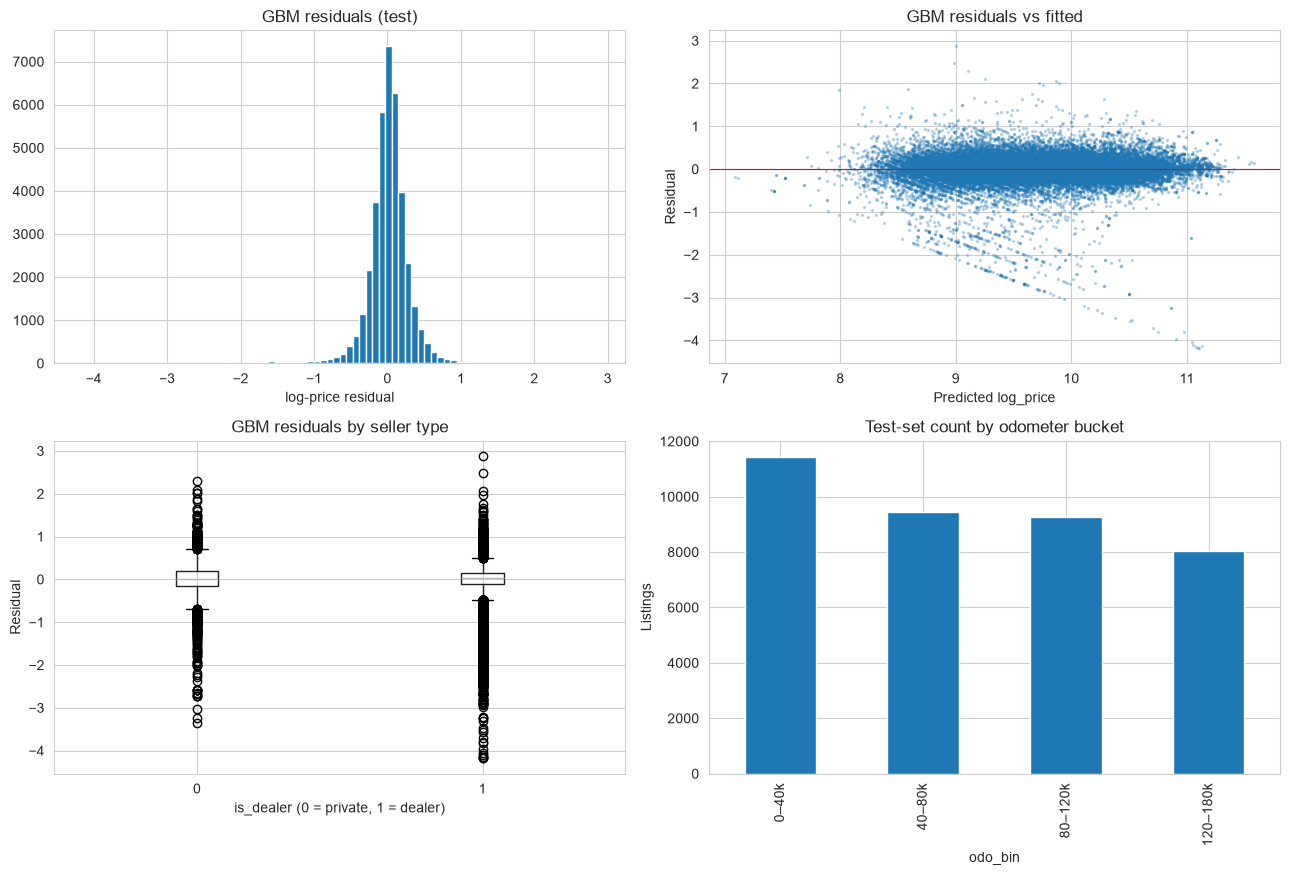

Residual summary by seller type (log-price units):
             count   mean    std    min    25%    50%    75%    max
is_dealer                                                          
0           6044.0 -0.002  0.377 -3.359 -0.167  0.009  0.187  2.288
1          32195.0  0.002  0.318 -4.184 -0.104  0.021  0.141  2.885


In [23]:
# High-level residuals on the held-out test set.
gbm_test_pred = gbm_final.predict(test[PREDICTORS]) # Predictions from the GBM model on the test set
ols_test_pred = ols_model.predict(X_test_ols) # Predictions from the OLS model on the test set

#Compute residuals for both models
gbm_resid = y_test.values - gbm_test_pred
ols_resid = y_test.values - ols_test_pred

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].hist(gbm_resid, bins=80)
axes[0, 0].set_title("GBM residuals (test)")
axes[0, 0].set_xlabel("log-price residual")

axes[0, 1].scatter(gbm_test_pred, gbm_resid, s=2, alpha=0.25)
axes[0, 1].axhline(0, color="red", linewidth=0.8)
axes[0, 1].set_title("GBM residuals vs fitted")
axes[0, 1].set_xlabel("Predicted log_price")
axes[0, 1].set_ylabel("Residual")

# Residuals by listing type
test_res = test[["is_dealer"]].copy()
test_res["resid"] = gbm_resid
test_res.boxplot(column="resid", by="is_dealer", ax=axes[1, 0])
axes[1, 0].set_title("GBM residuals by seller type")
axes[1, 0].set_xlabel("is_dealer (0 = private, 1 = dealer)")
axes[1, 0].set_ylabel("Residual")

# Residuals by mileage bucket (checks whether the model misfits high-mileage cars)
test_res["odo_bin"] = pd.cut(test["odometer"],
                             bins=[0, 40_000, 80_000, 120_000, 180_000],
                             labels=["0–40k", "40–80k", "80–120k", "120–180k"])
test_res["odo_bin"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Test-set count by odometer bucket")
axes[1, 1].set_ylabel("Listings")

plt.suptitle("")
plt.tight_layout()
plt.savefig(FIG_DIR / "gbm_residuals.png", dpi=150)
plt.show()

print("Residual summary by seller type (log-price units):")
print(test_res.groupby("is_dealer")["resid"].describe().round(3))

We can then flag the most mispriced listings in dollar terms. `exp` inverts `log_price`. 

In [24]:
flagged = test.copy()
flagged["actual_price"] = np.exp(flagged[TARGET])
flagged["pred_price"]   = np.exp(gbm_test_pred)
flagged["pct_gap"]      = (flagged["actual_price"] - flagged["pred_price"]) \
                          / flagged["pred_price"] * 100

display_cols = ["manufacturer", "type", "year", "odometer",
                "is_dealer", "actual_price", "pred_price", "pct_gap"]

print("Most underpriced by GBM (largest negative pct_gap):")
print(flagged.nsmallest(15, "pct_gap")[display_cols].round(1).to_string(index=False))

print("\nMost overpriced by GBM (largest positive pct_gap):")
print(flagged.nlargest(15, "pct_gap")[display_cols].round(1).to_string(index=False))

Most underpriced by GBM (largest negative pct_gap):
 manufacturer     type   year  odometer  is_dealer  actual_price  pred_price  pct_gap
         ford    truck 2019.0   30377.0          1        1008.0     66130.6    -98.5
          gmc  Unknown 2020.0   23396.0          1        1030.0     66588.7    -98.5
         ford    truck 2018.0   67043.0          1        1015.0     64717.8    -98.4
         ford    truck 2018.0   49772.0          1        1085.0     68208.0    -98.4
     cadillac      SUV 2018.0   43037.0          1        1028.0     62900.8    -98.4
     cadillac      SUV 2018.0   49342.0          1        1091.0     62404.0    -98.3
          gmc    truck 2015.0   58355.0          1        1030.0     54504.3    -98.1
         ford    truck 2018.0   14120.0          1        1029.0     46520.3    -97.8
      lincoln      SUV 2020.0   19646.0          1        1312.0     58636.2    -97.8
        rover      SUV 2019.0   26916.0          1        1089.0     44748.4    -97.6
me

### Interpretation

We see that GBM residuals are roughly symmetric, with a long left tail (a handful of catastrophic underpricings as expected). Furthermore, residual fan-out at high fitted values is visible, meaning the model may be less confident aboout expensive cars. Private listings also have roughly ~18% wider residuals (0.377 vs 0.18 std), meaning private-party pricing is less standardized. 

Its also important to note, the extreme residuals seem to be mostly data-entry errors or scrap vehicles, not real mispricings. The most "underpriced" listings are 2015-2019 trucks and SUVs priced at $1,000 - $1,300 against predictions in the $25k - 66k range. 

## Conclusions 

Considering our client question: 

"Given a veichle's characteristics, what asking price is typical, and which attributes are associated with higher posted prices?" 

- A **gradient-boosting model explains ~79% of the variance** in posted log-price, cutting error to ~$0.20 log-units (roughly $2,000-3,000 in dollar terms at median prices). OLS captures ~69% and is nearly as good with interpretable coefficients. 
- **Age and mileage are the dominant pricing factors**, contributing roughly twice as much as any other feature. 
- **Configuration** (cylinders, drive type, body type, fuel) is the next tier; geography is present but a distant third. 
- **Dealers post ~13% higher** than comparable private listings, and this premium does not materially distort attribute coefficients. 
- The **"flag mispriced listings"** works, but part of what it flags is price-entry errors and distressed listings. 

## Next Steps - `04_analysis.ipynb`

This notebook has produced four deliverables from the proposal: a baseline, an interpretable OLS model, regularized variants, a gradient-boosted model, a dealer-only sensitivity check, and a residual analysis with a mispricing flag. These results will feed directly into `04_analysis.ipynb` and the final report. 

**Four items remain:**

1. Refine the mispricing flag before reporting it
The current flag is a percentage gap on `exp(price)`, which is dominated by listings near the $1,000 floor that are either data-entry errors or distressed postings. Before any mispricing statistics are reported: 
- We must try to trim the flagged sample to **$3,000 - $150,000**. 
- Replace `pct_gap` with a **log-residual z-score**, and define "mispriced" as the 5th / 95th percentile of the test-set residual distribution. 
- Re-run the top/bottom listings on the trimmed sample. The glags that remain after this step are the ones worth interpreting as real pricing anomalies. 

2. Characterize what the flags have in common
We can group the flagged listings by `manufacturer`, `condition`, `year` x `odometer` bucket, and `is_dealer`. Two findings are already visible in the current residual plots and would be worth investigating: 
- **Private listings have ~18% wider residuals**, which suggests less standardized pricing and a wider prediction band on that segment. 
- **`condition_Unknown` and `cylinders_Unknown` carry real signal** in the OLS model (both negative, both significant), meaning listings that leave those fields blank price differently from listings that fill them in. 

3. Build a business-facing pricing band and depreciation schedule
The client question is not "what is the predicted log-price?" - it is "what range should I post at?" Using the test-set residuals, we can construct an **80% prediction band** around each prediction, then: 
- Plot predicted price vs `year` (holding other features at the median) to answer "what does a year of age cost?" in dollars. 
- Plot predicted price vs `odometer` for the same reason. 
- Conclude `04_analysis.ipynb` with 3-4 hypothetical listings run through the model to demonstrate the band in action. 

4. One open limitation to document
The GBM used its full `max_iter` budget (2,000) without early stopping. The current results are strong (test R^2 = 0.788, RMSE = 0.328), but the model was not given the chance to plateau. This may be more of a limitation to state in the final report rather than a blocker for `04_analysis.ipynb`. We could bump up `max_iter` to 3,000 and refit if time allows in `04_analysis.ipynb`. 

### Deliverables still outstanding

| Deliverable | Location |
|---|---|
| Final Project Progress Report (Nov 5th) - Results & Next Steps | `final_project_progress_report.ipynb` |
| Residual analysis, mispricing detection, business framing | `04_analysis.ipynb` |
| Executive summary, methodology, results, limitations | Final presentation & written report |